<a href="https://colab.research.google.com/github/tamarajovicic1/Data-Science-Masters/blob/main/breast-cancer-analysis/breast_cancer_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Opis i cilj projekta:

---
Cilj ovog projekta je da se sprovede analiza podataka kroz tri faze:


1.   Čišćenje podataka. U ovoj fazi će biti uklonjene nepotrebne kolone, duplikati i nekozistentni zapisi iz skupa podataka. Takođe će biti standardizovani formati (npr. brojevi) radi bolje analize. Cilj je obezbediti tačnost i konzistentnost podataka.
2.   Statistička eksplorativna analiza (EDA). Ovom analizom se omogućava bolji uvid u strukturu podataka. Koristiće se
grafikoni (histogrami, scatter plot-ovi, box plot-ovi) i korelaciona analiza kako bi se otkrili obrasci i uočile značajne varijable.
3. Feature engineering. To uključuje transformaciju postojećih karakteristika, kreiranje novih karakteristika na osnovu problema, skaliranje numeričkih vrednosti i enkodiranje kategorijskih promenljivih. Cilj je bio unapređenje kvaliteta ulaznih podataka za buduće modele.




# **1. Čišćenje podataka**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df=pd.read_csv('data.csv')

In [ ]:
#čitanje tabele
df

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN


In [ ]:
#prikaz prvih 5 redova
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [ ]:
#čišćenje nepotrebnih podataka
#brisanje ne potrebne kolone
df_cleaned = df.drop(columns=["Unnamed: 32"], errors="ignore")

In [ ]:
#uklanjanje suvišnih razmaka u svim tekstualnim kolonama
df = df.apply(lambda x: x.str.strip() if x.dtype == "object" else x)

In [ ]:
#provera i konverzija svih numeričkih vrednosti u float ako su greškom očitane kao objekti
for col in df.columns:
    if df[col].dtype == "object":
        try:
            df[col] = df[col].str.replace(",", ".").astype(float)
        except:
            continue

In [ ]:
#provera duplikata
duplicates = df_cleaned.duplicated().sum()

In [ ]:
#provera za nedostajuće vrednosti
missing_values = df_cleaned.isnull().sum()

In [ ]:
#podela po dijagnozama (B - Benigni, M - Maligni)
class_distribution = df_cleaned['diagnosis'].value_counts()

In [ ]:
#prikaz dobijenih rezultata
duplicates, missing_values[missing_values > 0], class_distribution

(np.int64(0),
 Series([], dtype: int64),
 diagnosis
 B    357
 M    212
 Name: count, dtype: int64)

Zaključak ove analize:

---


Sve duple informacije iz dataset-a su uklonjene, nema više nedostajućih vrednosti i nepotrebne kolone Unnamed. Podaci su na kraju prikazani koliko ih ima sa vrednošću B i vrednošću M.




# **2. Statistička eksploracija**

In [ ]:
#pregled osnovnih statistika
print(df.describe())

                 id  radius_mean  texture_mean  perimeter_mean    area_mean  \
count  5.690000e+02   569.000000    569.000000      569.000000   569.000000   
mean   3.037183e+07    14.127292     19.289649       91.969033   654.889104   
std    1.250206e+08     3.524049      4.301036       24.298981   351.914129   
min    8.670000e+03     6.981000      9.710000       43.790000   143.500000   
25%    8.692180e+05    11.700000     16.170000       75.170000   420.300000   
50%    9.060240e+05    13.370000     18.840000       86.240000   551.100000   
75%    8.813129e+06    15.780000     21.800000      104.100000   782.700000   
max    9.113205e+08    28.110000     39.280000      188.500000  2501.000000   

       smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
count       569.000000        569.000000      569.000000           569.000000   
mean          0.096360          0.104341        0.088799             0.048919   
std           0.014064          0.052813     

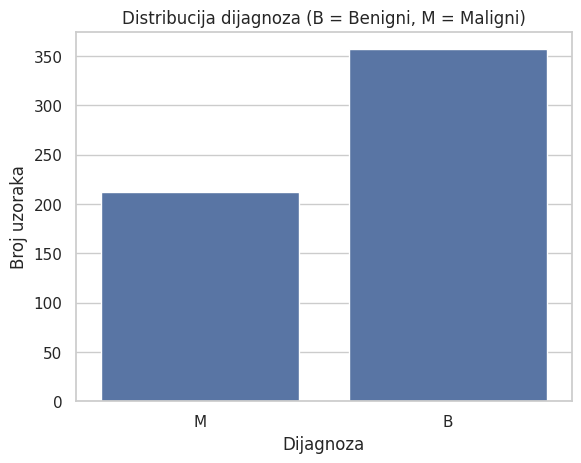

In [ ]:
#pregled broja benignih i malignih tumora
sns.countplot(x='diagnosis', data=df)
plt.title('Distribucija dijagnoza (B = Benigni, M = Maligni)')
plt.xlabel('Dijagnoza')
plt.ylabel('Broj uzoraka')
plt.show()

In [ ]:
#statistika po klasama, uporedjivanje srednje vrednosti osobina po klasama (B ili M)
df_grouped = df.groupby('diagnosis').mean()
#top 10 osobina kod malignih
print(df_grouped.T.sort_values(by='M', ascending=False).head(10))

diagnosis                   B             M
id               2.654382e+07  3.681805e+07
area_worst       5.588994e+02  1.422286e+03
area_mean        4.627902e+02  9.783764e+02
perimeter_worst  8.700594e+01  1.413703e+02
perimeter_mean   7.807541e+01  1.153654e+02
area_se          2.113515e+01  7.267241e+01
texture_worst    2.351507e+01  2.931821e+01
texture_mean     1.791476e+01  2.160491e+01
radius_worst     1.337980e+01  2.113481e+01
radius_mean      1.214652e+01  1.746283e+01


<ipython-input-63-6b01a474ff0e>:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='diagnosis', y=feature, palette='coolwarm')


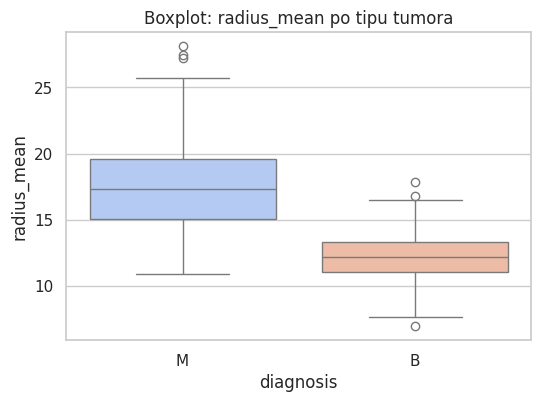

<ipython-input-63-6b01a474ff0e>:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='diagnosis', y=feature, palette='coolwarm')


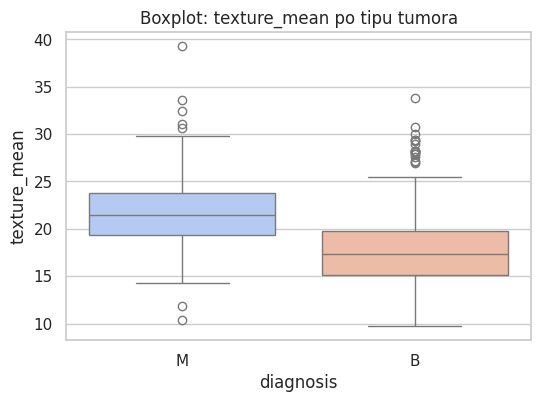

<ipython-input-63-6b01a474ff0e>:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='diagnosis', y=feature, palette='coolwarm')


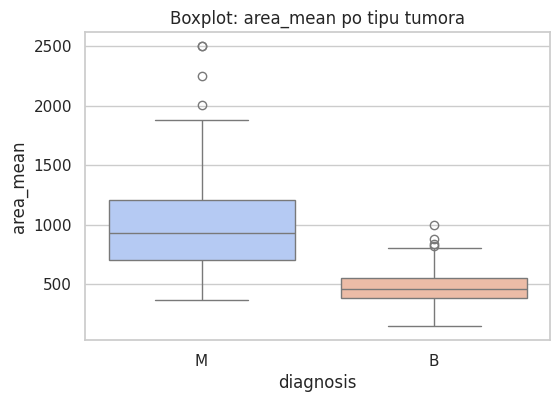

<ipython-input-63-6b01a474ff0e>:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='diagnosis', y=feature, palette='coolwarm')


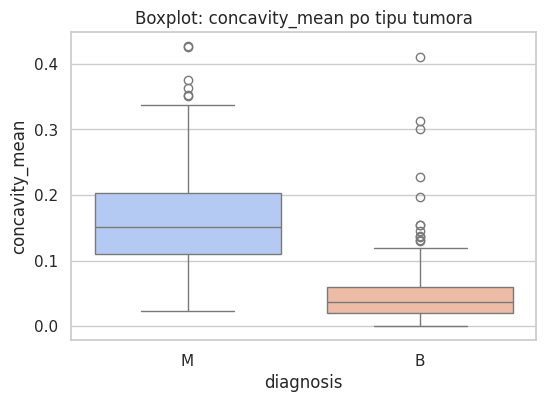

In [ ]:
#prikaz razlika u distribuciji između benignih i malignih tumora
top_features = ['radius_mean', 'texture_mean', 'area_mean', 'concavity_mean']

for feature in top_features:
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=df, x='diagnosis', y=feature, palette='coolwarm')
    plt.title(f"Boxplot: {feature} po tipu tumora")
    plt.show()

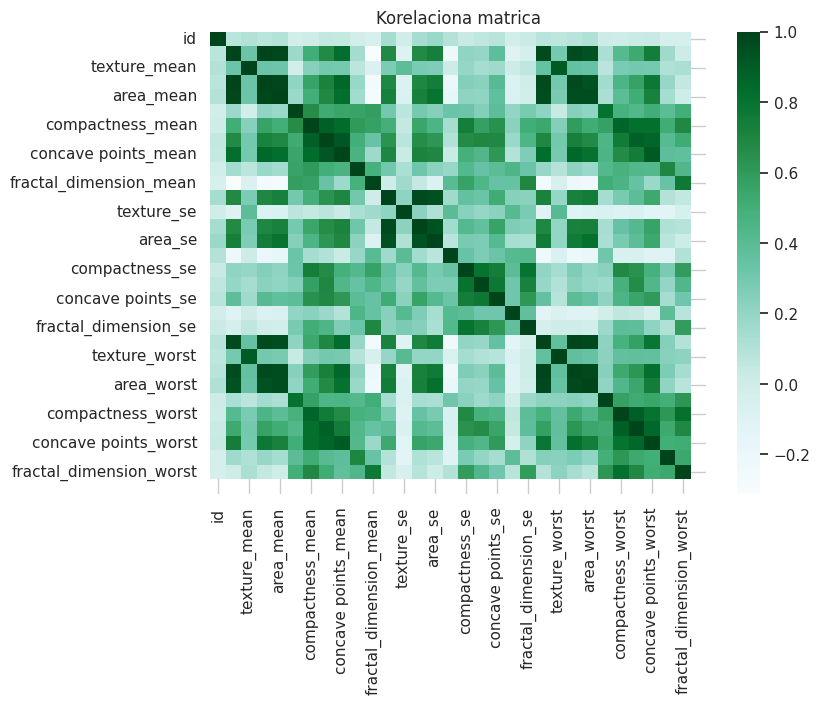

In [ ]:
#korelaciona matrica - heatmap
plt.figure(figsize=(8,6))
sns.heatmap(df.select_dtypes(include='number').corr(), cmap='BuGn', annot=False)
plt.title("Korelaciona matrica")
plt.show()

In [ ]:
#kreiranje numeričke kolone za dijagnozu (B = 0, M = 1)
df['diagnosis_num'] = df['diagnosis'].map({'B': 0, 'M': 1})

In [ ]:
#izbor samo numeričkih kolona
df_numeric = df.select_dtypes(include='number')

In [ ]:
#korelacija osobina sa numeričkom dijagnozom
correlations = df_numeric.corr()['diagnosis_num'].drop(['diagnosis_num', 'id'], errors='ignore').sort_values(ascending=False)

In [ ]:
print("Top 10 najpozitivnije korelisanih osobina sa malignim tumorima:")
print(correlations.head(10))

print("\nTop 10 najnegativnije korelisanih osobina (indikatori benignih tumora):")
print(correlations.tail(10))

Top 10 najpozitivnije korelisanih osobina sa malignim tumorima:
concave points_worst    0.793566
perimeter_worst         0.782914
concave points_mean     0.776614
radius_worst            0.776454
perimeter_mean          0.742636
area_worst              0.733825
radius_mean             0.730029
area_mean               0.708984
concavity_mean          0.696360
concavity_worst         0.659610
Name: diagnosis_num, dtype: float64

Top 10 najnegativnije korelisanih osobina (indikatori benignih tumora):
symmetry_mean              0.330499
fractal_dimension_worst    0.323872
compactness_se             0.292999
concavity_se               0.253730
fractal_dimension_se       0.077972
symmetry_se               -0.006522
texture_se                -0.008303
fractal_dimension_mean    -0.012838
smoothness_se             -0.067016
Unnamed: 32                     NaN
Name: diagnosis_num, dtype: float64


<ipython-input-69-f39a6dccfb6e>:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_pos_corr.values, y=top_pos_corr.index, palette="Purples")
<ipython-input-69-f39a6dccfb6e>:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_neg_corr.values, y=top_neg_corr.index, palette="Reds_r")


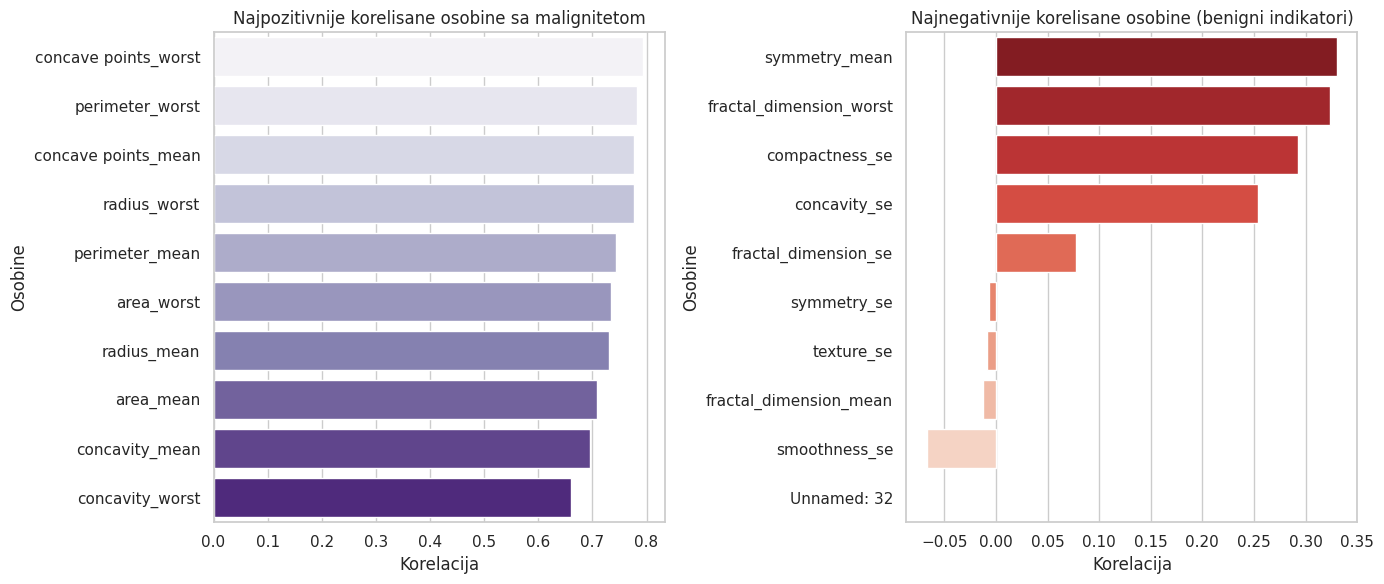

In [ ]:
#odvojeno top 10 pozitivnih i negativnih korelacija
top_pos_corr = correlations.head(10)
top_neg_corr = correlations.tail(10)

#stil
sns.set(style="whitegrid")

plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
sns.barplot(x=top_pos_corr.values, y=top_pos_corr.index, palette="Purples")
plt.title("Najpozitivnije korelisane osobine sa malignitetom")
plt.xlabel("Korelacija")
plt.ylabel("Osobine")
plt.subplot(1, 2, 2)
sns.barplot(x=top_neg_corr.values, y=top_neg_corr.index, palette="Reds_r")
plt.title("Najnegativnije korelisane osobine (benigni indikatori)")
plt.xlabel("Korelacija")
plt.ylabel("Osobine")

plt.tight_layout()
plt.show()

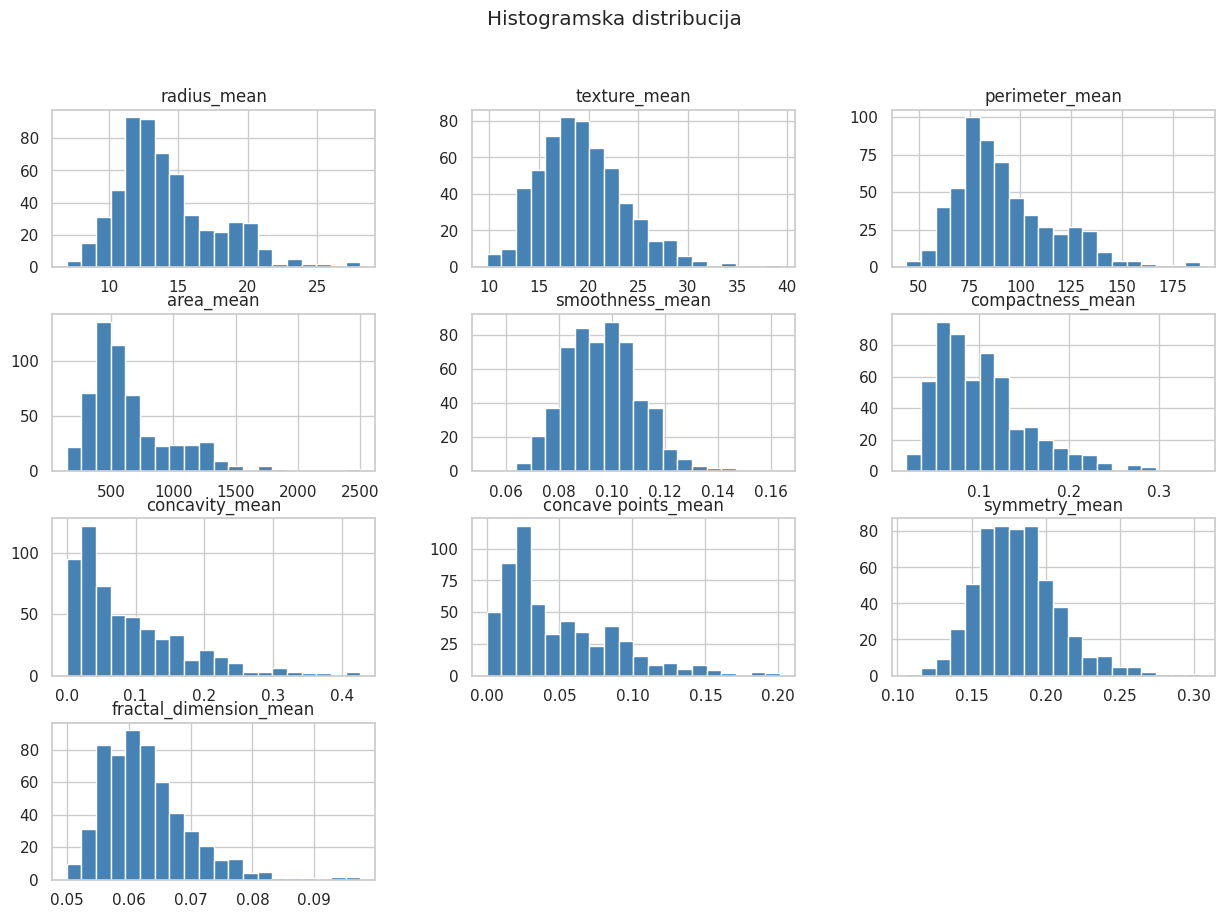

In [ ]:
#histogram za numeričke kolone (osim prve dve kolone)
df[df.columns[2:12]].hist(bins=20, figsize=(15,10), color='steelblue')
plt.suptitle("Histogramska distribucija")
plt.show()

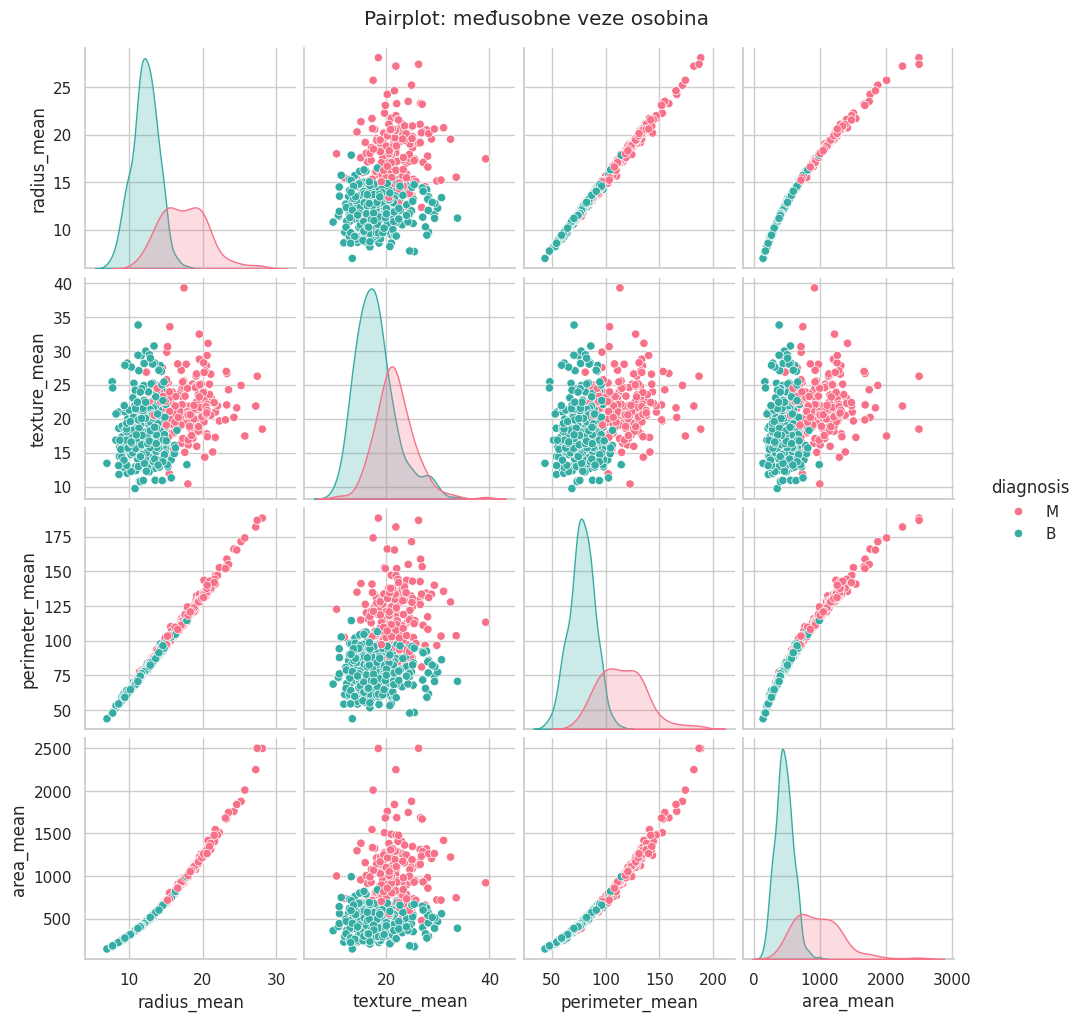

In [ ]:
#pairplot između osobina i dijagnoze
sns.pairplot(df[['diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean']], hue='diagnosis', palette='husl')
plt.suptitle("Pairplot: međusobne veze osobina", y=1.02)
plt.show()

<ipython-input-72-58f4a27b1076>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='diagnosis', y='area_mean', data=df, palette="muted")


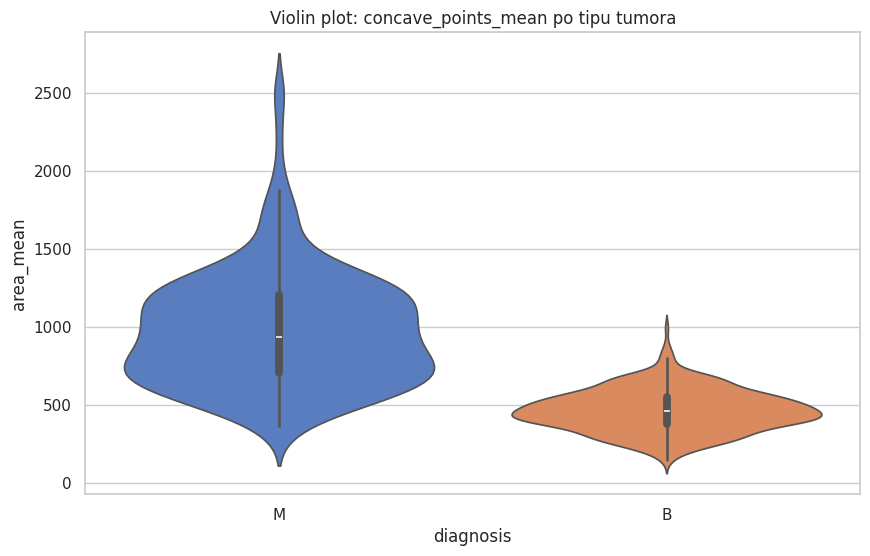

In [ ]:
#violin grafik(kombinacija boxplot-a i kernel density)
plt.figure(figsize=(10,6))
sns.violinplot(x='diagnosis', y='area_mean', data=df, palette="muted")
plt.title("Violin plot: concave_points_mean po tipu tumora")
plt.show()

In [ ]:
#z-score analiza za detekciju odstupanja u podacima
from scipy.stats import zscore
z_scores = df.select_dtypes(include='number').apply(zscore)
#prikaz odstupanja (z-score > 3)
outliers = (z_scores.abs() > 3).sum().sort_values(ascending=False)
print("Broj odstupanja po kolonama:\n", outliers.head(10))

Broj odstupanja po kolonama:
 compactness_se             12
id                         11
symmetry_se                11
fractal_dimension_se       10
area_worst                 10
compactness_worst          10
concavity_mean              9
texture_se                  9
compactness_mean            9
fractal_dimension_worst     9
dtype: int64


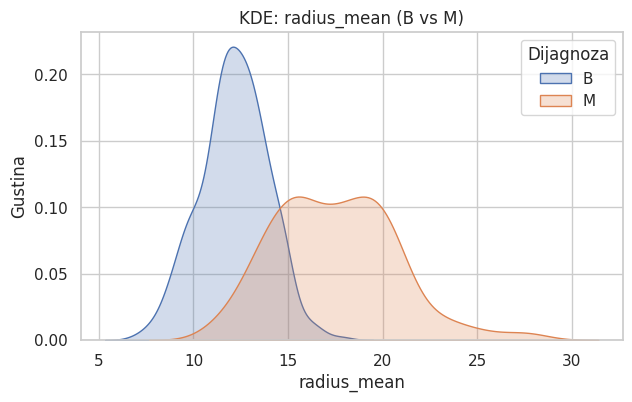

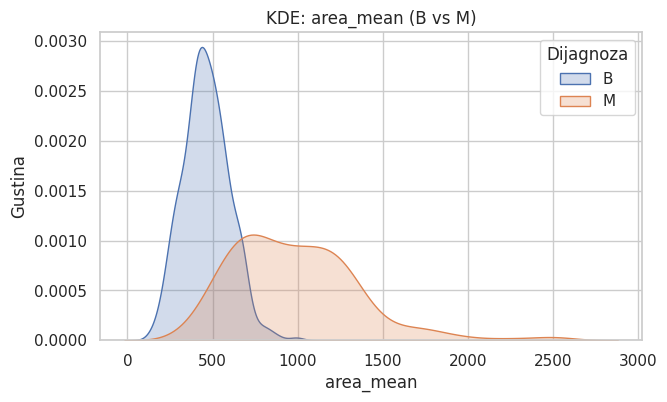

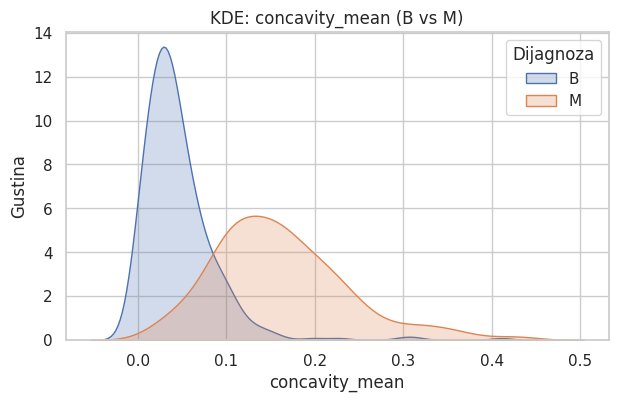

In [ ]:
#kernel density estimate
features_to_plot = ['radius_mean', 'area_mean', 'concavity_mean']

for feature in features_to_plot:
    plt.figure(figsize=(7, 4))
    for diag in ['B', 'M']:
        subset = df[df['diagnosis'] == diag]
        sns.kdeplot(subset[feature], label=f'{diag}', fill=True)
    plt.title(f"KDE: {feature} (B vs M)")
    plt.xlabel(feature)
    plt.ylabel("Gustina")
    plt.legend(title='Dijagnoza')
    plt.show()

Zaključak ovog koda:

---

1. Distribucija dijagnoza:
Vizualizacija pomoću countplot prikazuje broj benignih (B) i malignih (M) tumora u skupu podataka.
2. Statistika po klasama (benigni vs maligni): Kroz grupisanje po dijagnozi i upoređivanje srednjih vrednosti osobina za benigni i maligni tip, možemo primetiti razlike u vrednostima osobina između dva tipa tumora. Na primer, maligni tumori često imaju veće vrednosti za osobine kao što je area_mean.
3. Boxplot-ovi za upoređivanje distribucije: Vizualizacija pomoću boxplot grafika pokazuje razlike u distribuciji nekoliko ključnih osobina (radius_mean, texture_mean, area_mean, concavity_mean) između benignih i malignih tumora. Ovi grafici mogu pomoći u identifikovanju varijacija u vrednostima između različitih tipova tumora.
4. Korelacija između osobina i dijagnoze: Korelaciona matrica i analiza korelacije sa diagnosis_num pokazuju koje osobine imaju najjaču korelaciju sa malignim tumorima. To omogućava identifikaciju ključnih faktora koji mogu biti indikatori maligniteta, kao što su radius_mean, concavity_mean i texture_mean, dok negativne korelacije sa benignim tumorima uključuju osobine poput smoothness_mean.
5. Vizualizacija pozitivnih i negativnih korelacija: Bar grafici za pozitivne i negativne korelacije jasno prikazuju koji su faktori najviše povezani sa malignim tumorima, a koji sa benignim, čime se može usmeriti dalja istraživanja na specifične osobine koje najviše utiču na dijagnozu.
6. Distribucija osobina: Histogrami omogućavaju vizualizaciju raspodele osobina, što može otkriti asimetriju ili nenormalne raspodele podataka. To je važno za razumevanje razlika između osobina i potrebe za normalizaciju ili transformaciju podataka.
7. Pairplot za međusobne veze osobina: Pairplot omogućava analizu odnosa između različitih osobina u kontekstu dijagnoze, što može pomoći u prepoznavanju obrazaca u podacima koji bi mogli ukazivati na specifične karakteristike malignih ili benignih tumora.
8. Violin plot za detaljan prikaz distribucije: Violin grafici omogućavaju detaljan uvid u gustinu podataka, što je korisno za vizualizaciju razlika između benignih i malignih tumora na osnovu specifičnih osobina.
9. Z-score analiza i detekcija odstupanja: Analiza z-score-a pomaže u identifikovanju odstupanja u podacima, što može ukazivati na neobične uzorke ili greške u podacima.
10. Kernel Density Estimate (KDE): KDE omogućava vizualizaciju gustine distribucije osobina, što može biti korisno za prepoznavanje suptilnih razlika između benignih i malignih tumora koje možda nisu očigledne iz drugih grafika.

# **3. Feature Engineering**

In [ ]:
#odnos obima i površine tumora
df['perimeter_area_ratio'] = df['perimeter_mean'] / df['area_mean']
#razlika između maksimalnog i srednjeg radijusa
df['radius_diff'] = df['radius_worst'] - df['radius_mean']

In [ ]:
# Binning za area_mean u 4 kvantila
df['area_mean_bin'] = pd.qcut(df['area_mean'], q=4, labels=["low", "mid-low", "mid-high", "high"])

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
#odabir samo numeričkih kolona (isključujući 'id' i 'diagnosis_num' jer nisu korisni za skaliranje)
scaled_features = scaler.fit_transform(df.select_dtypes(include='number').drop(columns=['id', 'diagnosis_num']))
df_scaled = pd.DataFrame(scaled_features, columns=df.select_dtypes(include='number').drop(columns=['id', 'diagnosis_num']).columns)

/usr/local/lib/python3.11/dist-packages/sklearn/utils/extmath.py:1101: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
/usr/local/lib/python3.11/dist-packages/sklearn/utils/extmath.py:1106: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
/usr/local/lib/python3.11/dist-packages/sklearn/utils/extmath.py:1126: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


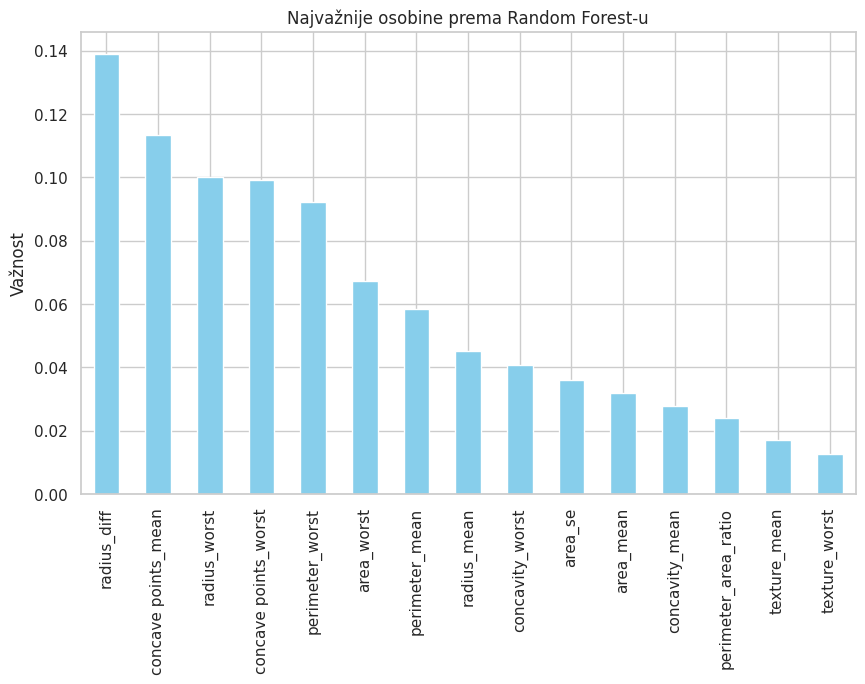

In [ ]:
from sklearn.ensemble import RandomForestClassifier

X = df.select_dtypes(include='number').drop(columns=['id', 'diagnosis_num'])
y = df['diagnosis_num']
#Random Forest klasifikator sa 100 stabala
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X, y)
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(10,6))
importances.head(15).plot(kind='bar', color='skyblue')
plt.title("Najvažnije osobine prema Random Forest-u")
plt.ylabel("Važnost")
plt.show()

Zaključak ovog dela koda:

---

U ovom delu analize izvršeno je dalje unapređenje skupa podataka dodavanjem novih osobina kao što su odnos obima i površine tumora (perimeter_area_ratio) i razlika između maksimalnog i prosečnog radijusa (radius_diff), kao i kategorizacija površine tumora (area_mean_bin) u četiri kvantila. Podaci su zatim standardizovani korišćenjem StandardScaler kako bi se obezbedila uporedivost između različitih numeričkih osobina. Nakon pripreme podataka, treniran je Random Forest klasifikator koji je identifikovao najvažnije osobine za klasifikaciju tumora. Vizualizacija rezultata pokazuje koje osobine najviše doprinose razlikovanju između benignih i malignih tumora, pri čemu su osobine poput concave_points_mean, radius_worst, i perimeter_worst među najvažnijima. Ova analiza pomaže u boljem razumevanju faktora koji utiču na dijagnozu i može biti osnova za dalji razvoj prediktivnih modela.